# Braun et al. (2026), Supp. Figs. 3–5 — profile features, 2-D grids and motifs (WP0.2, WP0.3)

> Supp. 3: A asymmetry (position of the maximum) against offset; B range against width; C mean peak width against
> amplitude. Supp. 4: peak width and range over amplitude × width (b = 0), asymmetry and peak width over
> offset × amplitude (σ = 1 s). Supp. 5: motif abundances (reciprocal, divergent, convergent, chain) against offset,
> width and amplitude.

**Panels:** S3A–C · S4B, S4C, S4E, S4F · S5B · S5-extra (motifs of W_cp and of W − W_cp) · training performance
(Supp. 1F) per condition.

**Acceptance (spec WP0.2, WP0.3):** asymmetry ≈ 10–20 neurons up to b = 0.25, rising to ≈ 75 at b = 0.45; range falls
with width; peak width falls with amplitude; performance rises with amplitude and falls with offset; τ_div, τ_con,
τ_chn below 0.05 in absolute value; τ_rec rising with offset and width, and with amplitude up to 0.7.

Features follow Braun Methods lines 991–1012 on the mean-matrix profile (`seqnet.analysis.profile_features`, MATLAB
`smoothdata` emulated with std = window/5 [VERIFY A5]). Settings: those of `configs/wp0/braun_fig2.yaml` (dev).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seqnet.figures import Figure, style
from seqnet.experiments import wp0
from seqnet import conventions as cv
from seqnet.analysis.profile_features import profile_features
from seqnet.analysis.motifs import motifs

style()
fig = Figure("wp0", "braun_supp3")
cfg = Figure("wp0", "braun_fig2").config()
st, fp = cfg["settings"], cfg["features"]

def analyse(amp, width, offset):
    r = wp0.get(amp, width, offset, st)
    Wm = r.summary["mean_W"]
    pf = profile_features(cv.profile_from_matrix(Wm), fp["window"], fp["sigma_frac"], fp["prominence"])
    Wcp = cv.circulant_projection(Wm)
    m, mc, mr = motifs(Wm), motifs(Wcp), motifs(Wm - Wcp)
    test = r.summary["corr"][:, -r.config.n_test:].mean(1)
    return {"asym": pf.asymmetry, "range": pf.range, "peak_width": pf.peak_width, "self_w": pf.self_weight,
            **{f"{k}": m[k] for k in ("tau_rec", "tau_div", "tau_con", "tau_chn")},
            **{f"cp_{k}": mc[k] for k in ("tau_rec", "tau_div", "tau_con", "tau_chn")},
            **{f"res_{k}": mr[k] for k in ("tau_rec", "tau_div", "tau_con", "tau_chn")}}, test

def run_sweep(name, key):
    sw = cfg[name]; feats, tests = [], []
    for v in sw["values"]:
        p = {k: sw[k] for k in ("amp", "width", "offset") if k in sw}; p[key] = v
        f, t = analyse(p["amp"], p["width"], p["offset"]); feats.append(f); tests.append(t)
    keys = list(feats[0])
    fig.save(f"sweep_{key}", params=sw, values=np.array(sw["values"]), test_corr=np.stack(tests),
             **{k: np.array([f[k] for f in feats]) for k in keys})

run_sweep("offset_sweep", "offset"); run_sweep("width_sweep", "width"); run_sweep("amp_sweep", "amp")

## Supp. 3A–C — asymmetry vs offset, range vs width, mean peak width vs amplitude

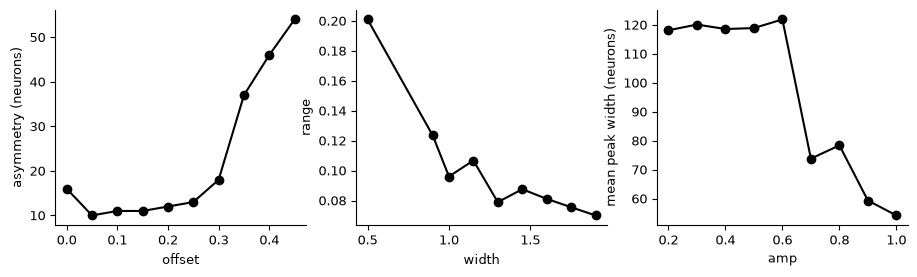

offset asym [16. 10. 11. 11. 12. 13. 18. 37. 46. 54.]
width range [0.201 0.124 0.096 0.107 0.079 0.088 0.081 0.076 0.07 ]
amp peak_width [118.137 120.112 118.571 118.894 121.885  73.796  78.408  59.348  54.206]


In [2]:
F, axs = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, (key, feat, lab) in zip(axs, [("offset", "asym", "asymmetry (neurons)"), ("width", "range", "range"), ("amp", "peak_width", "mean peak width (neurons)")]):
    d = fig.load(f"sweep_{key}"); ax.plot(d["values"], d[feat], "ko-"); ax.set_xlabel(key); ax.set_ylabel(lab)
fig.savefig("S3_features", F); plt.show()
for key, feat in [("offset", "asym"), ("width", "range"), ("amp", "peak_width")]:
    d = fig.load(f"sweep_{key}"); print(key, feat, np.round(d[feat], 3))

## Supp. 1F — training performance (test correlation) per condition

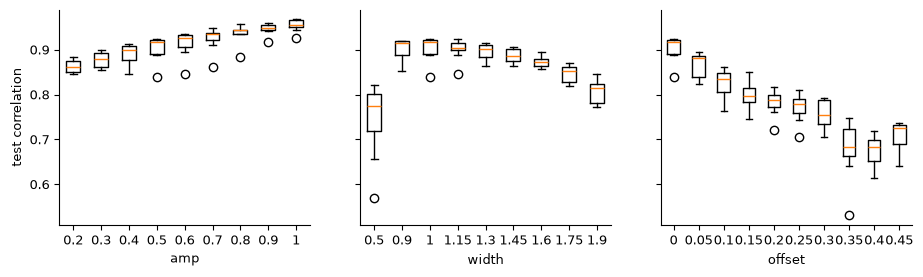

In [3]:
F, axs = plt.subplots(1, 3, figsize=(11, 2.8), sharey=True)
for ax, key in zip(axs, ["amp", "width", "offset"]):
    d = fig.load(f"sweep_{key}"); ax.boxplot(list(d["test_corr"]), tick_labels=[f"{v:g}" for v in d["values"]]); ax.set_xlabel(key)
axs[0].set_ylabel("test correlation")
fig.savefig("S1F_performance", F); plt.show()

## Supp. 4 — 2-D grids: amplitude × width (b = 0) and offset × amplitude (σ = 1 s)

In [4]:
def grid(name, k1, k2, fixed):
    g = cfg[name]; v1, v2 = g[k1 + "s"], g[k2 + "s"]
    out = {f: np.zeros((len(v1), len(v2))) for f in ("asym", "range", "peak_width", "tau_rec")}
    for i, a in enumerate(v1):
        for j, b in enumerate(v2):
            p = {fixed: g[fixed], k1: a, k2: b}
            f, _ = analyse(p["amp"], p["width"], p["offset"])
            for k in out: out[k][i, j] = f[k]
    fig.save(f"grid_{name}", params=g, v1=np.array(v1), v2=np.array(v2), **out)

grid("amp_width_grid", "amp", "width", "offset")
grid("offset_amp_grid", "offset", "amp", "width")

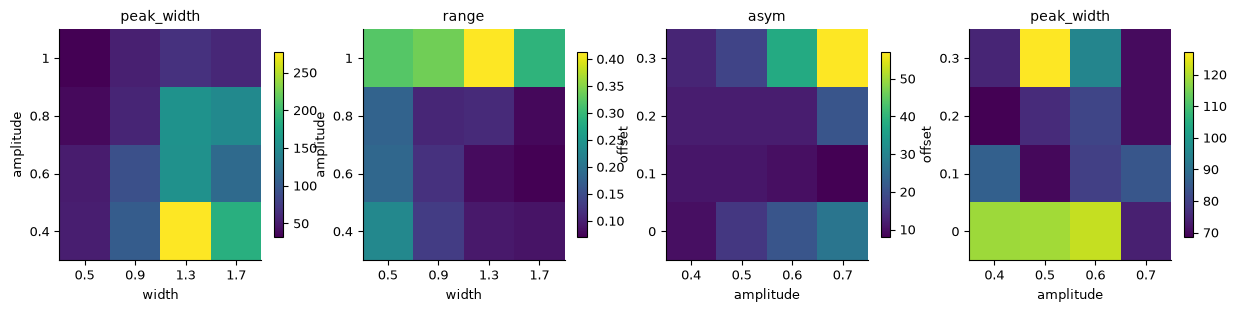

In [5]:
F, axs = plt.subplots(1, 4, figsize=(15, 3))
for ax, (nm, feat, xl, yl) in zip(axs, [("amp_width_grid", "peak_width", "width", "amplitude"), ("amp_width_grid", "range", "width", "amplitude"),
                                        ("offset_amp_grid", "asym", "amplitude", "offset"), ("offset_amp_grid", "peak_width", "amplitude", "offset")]):
    d = fig.load(f"grid_{nm}")
    im = ax.imshow(d[feat], origin="lower", aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(d["v2"])), [f"{v:g}" for v in d["v2"]]); ax.set_yticks(range(len(d["v1"])), [f"{v:g}" for v in d["v1"]])
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(feat); F.colorbar(im, ax=ax, shrink=0.8)
fig.savefig("S4_grids", F); plt.show()

## Supp. 5B — motif abundances (Braun eq. 14–15), plus the circulant part and the residual separately (spec WP0.3)

For any matrix with equal row and column sums the off-diagonal motifs equal −1/(N−1) ≈ −0.002 exactly (T15), so
"≈ 0" is the expectation for a translation-invariant matrix.

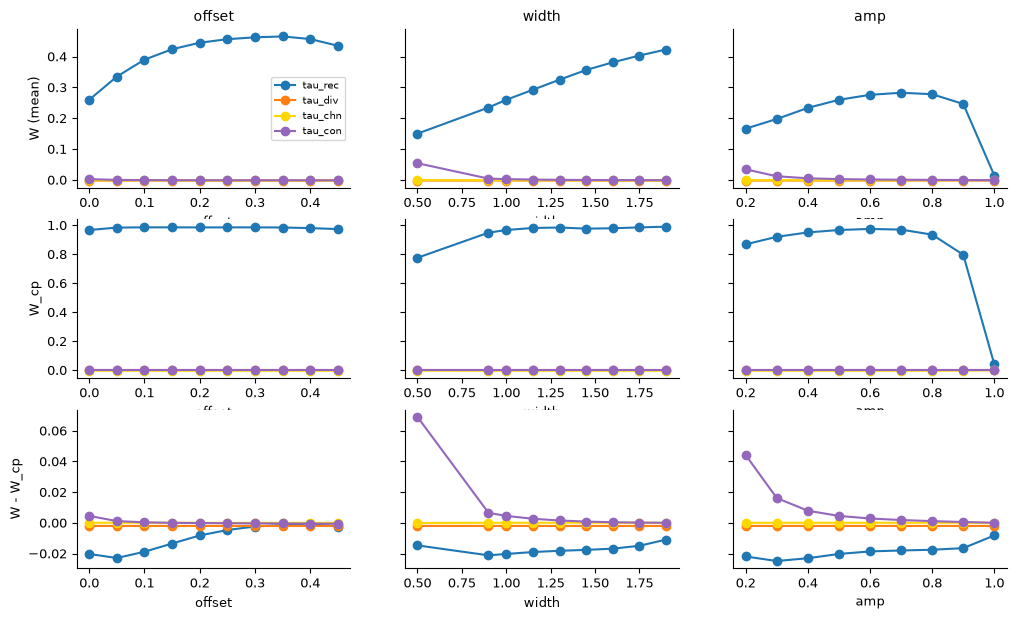

In [6]:
F, axs = plt.subplots(3, 3, figsize=(12, 7), sharey="row")
for col, key in enumerate(["offset", "width", "amp"]):
    d = fig.load(f"sweep_{key}")
    for row, pre in enumerate(["", "cp_", "res_"]):
        for k, c in zip(("tau_rec", "tau_div", "tau_chn", "tau_con"), ("tab:blue", "tab:orange", "gold", "tab:purple")):
            axs[row, col].plot(d["values"], d[pre + k], "o-", color=c, label=k)
        axs[row, col].set_xlabel(key)
    axs[0, col].set_title(key)
for row, lab in enumerate(["W (mean)", "W_cp", "W - W_cp"]): axs[row, 0].set_ylabel(lab)
axs[0, 0].legend(fontsize=7)
fig.savefig("S5_motifs", F); plt.show()

## Acceptance

In [7]:
o, w, a = fig.load("sweep_offset"), fig.load("sweep_width"), fig.load("sweep_amp")
low = o["asym"][o["values"] <= 0.25]
mono = lambda x, s: bool(np.all(np.diff(x) * s >= -1e-12))
corr_s = lambda x, y: float(np.corrcoef(x, y)[0, 1])
off_motifs = np.concatenate([d[k] for d in (o, w, a) for k in ("tau_div", "tau_con", "tau_chn")])
fig.checks([
    {"item": "asymmetry 10-20 neurons up to b = 0.25", "criterion": "all within [5, 30] (paper 10-20)", "value": low, "passed": bool(np.all((low >= 5) & (low <= 30)))},
    {"item": "asymmetry at b = 0.45 about 75 neurons", "criterion": "within factor 1.5 of 75", "value": float(o["asym"][-1]), "passed": bool(50 <= o["asym"][-1] <= 112.5)},
    {"item": "range falls with width", "criterion": "Spearman-like: corr(width, range) < -0.8", "value": corr_s(w["values"], w["range"]), "passed": corr_s(w["values"], w["range"]) < -0.8},
    {"item": "peak width falls with amplitude", "criterion": "corr(amp, peak width) < -0.8", "value": corr_s(a["values"], a["peak_width"]), "passed": corr_s(a["values"], a["peak_width"]) < -0.8},
    {"item": "performance rises with amplitude", "criterion": "corr(amp, median test corr) > 0.8", "value": corr_s(a["values"], np.median(a["test_corr"], 1)), "passed": corr_s(a["values"], np.median(a["test_corr"], 1)) > 0.8},
    {"item": "performance falls with offset", "criterion": "corr(offset, median test corr) < -0.8", "value": corr_s(o["values"], np.median(o["test_corr"], 1)), "passed": corr_s(o["values"], np.median(o["test_corr"], 1)) < -0.8},
    {"item": "off-diagonal motifs about 0", "criterion": "|tau_div|, |tau_con|, |tau_chn| < 0.05", "value": float(np.abs(off_motifs).max()), "passed": bool(np.abs(off_motifs).max() < 0.05)},
    {"item": "tau_rec range", "criterion": "reported (paper 0.55-0.8)", "value": [float(min(d["tau_rec"].min() for d in (o, w, a))), float(max(d["tau_rec"].max() for d in (o, w, a)))], "passed": None},
    {"item": "tau_rec rises with offset and width", "criterion": "corr > 0.5 for both", "value": [corr_s(o["values"], o["tau_rec"]), corr_s(w["values"], w["tau_rec"])],
     "passed": corr_s(o["values"], o["tau_rec"]) > 0.5 and corr_s(w["values"], w["tau_rec"]) > 0.5},
])

[PASS] asymmetry 10-20 neurons up to b = 0.25: [16. 10. 11. 11. 12. 13.]
[PASS] asymmetry at b = 0.45 about 75 neurons: 54.0
[PASS] range falls with width: -0.8718048678834952
[PASS] peak width falls with amplitude: -0.8908129043353226
[PASS] performance rises with amplitude: 0.9745785748032733
[PASS] performance falls with offset: -0.9439541229370441
[FAIL] off-diagonal motifs about 0: 0.05420327956708958
[info] tau_rec range: [0.01425243337503026, 0.4651939933601902]
[PASS] tau_rec rises with offset and width: [0.8007412492574406, 0.996261122616787]


WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_supp3/acceptance.json')